In [1]:
import duckdb as db
import polars as pl
import os, glob
import numpy as np
import matplotlib.pyplot as plt
from cfg import SHORT

In [2]:
DATASET = os.path.join("..", "data", "raw")
PROCESSED = os.path.join("..", "data", "processed")
DB_PATH = os.path.join("..", "data", "raw", "sintef_ocean.db")

In [3]:
short2name = {v: k for k, v in SHORT.items()}

In [6]:
conn = db.connect(database=DB_PATH)
metrics_raw_long = conn.execute("SELECT timestamp, short_name, value FROM metrics_raw").pl()
noon_reports = conn.execute("SELECT * FROM noon_reports").pl()
jan25 = conn.execute("SELECT * FROM jan25").pl()
conn.close()
metrics_wide = metrics_raw_long.pivot(index="timestamp", on="short_name", values="value", aggregate_function="mean").sort("timestamp")

c:\AID Project\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


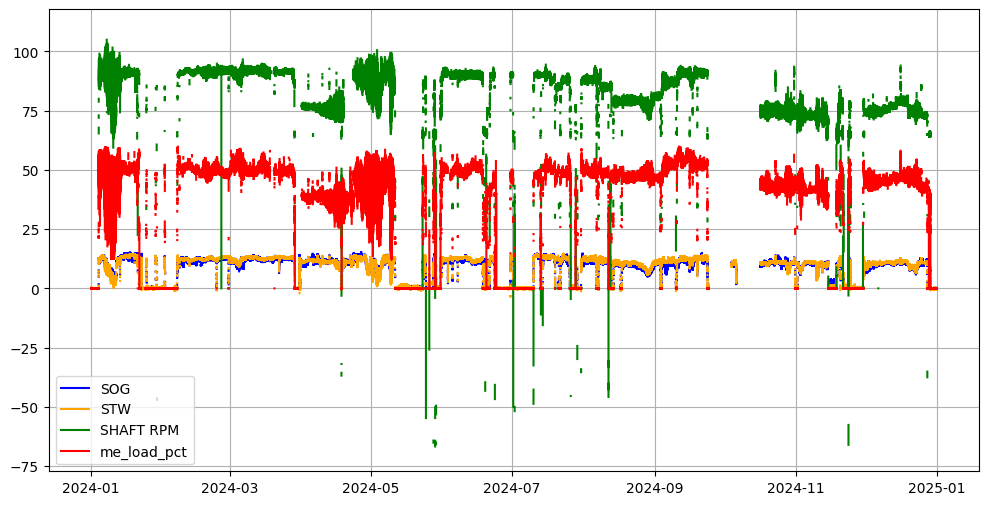

In [9]:
plt.figure(figsize=(12, 6))
plt.grid(True)
plt.plot(metrics_wide["timestamp"].to_numpy(), metrics_wide["sog_kn"].to_numpy(), color = "blue", label = "SOG")
plt.plot(metrics_wide["timestamp"].to_numpy(), metrics_wide["stw_kn"].to_numpy(), color = "orange", label = "STW")
plt.plot(metrics_wide["timestamp"].to_numpy(), metrics_wide["me_rpm"].to_numpy(), color = "green", label = "SHAFT RPM")
plt.plot(metrics_wide["timestamp"].to_numpy(), metrics_wide["me_load_pct"].to_numpy(), color = "red", label = "me_load_pct")
plt.legend()
plt.show()

In [11]:
def identify_trips(
    df: pl.DataFrame,
    time_col: str = "timestamp",
    stop_speed_kn: float = 1.0,
    min_stop_minutes: float = 30,
    max_gap_minutes: float = 15,
):
    # Assumes one vessel and an already-parsed Datetime column.
    # Extract valid SOG observations independently of other sensors.
    x = (df.select(pl.col(time_col).alias("timestamp"), "sog_kn",).drop_nulls().filter(pl.col("sog_kn").is_finite()
            & (pl.col("sog_kn") >= 0)).unique()  # Remove identical timestamp–speed pairs.
        .sort("timestamp"))
    if x.is_empty():
        raise ValueError("No valid SOG observations.")

    if x["timestamp"].n_unique() != x.height:
        raise ValueError(
            "Resolve conflicting SOG readings at duplicate timestamps."
        )

    # A recording gap begins a new observed section.
    x = x.with_columns((pl.col("timestamp").diff().dt.total_seconds() > max_gap_minutes * 60).fill_null(True)
        .alias("_new_block"),
        (pl.col("sog_kn") <= stop_speed_kn).alias("_low_speed"),
    )

    # Identify consecutive runs of low speed or movement.
    # A recording gap always starts a new run.
    x = x.with_columns(((pl.col("_low_speed") != pl.col("_low_speed").shift(1))| pl.col("_new_block"))
        .fill_null(True).cast(pl.Int64).cum_sum()
        .alias("_run"),

        pl.col("_new_block")
        .shift(-1)
        .fill_null(True)
        .alias("_block_end"),
    )

    # Observed elapsed time within each run.
    x = x.with_columns(
        (
            pl.col("timestamp").max().over("_run")
            - pl.col("timestamp").min().over("_run")
        )
        .dt.total_seconds()
        .alias("_run_seconds")
    )

    # Only sufficiently long low-speed runs count as stops.
    x = x.with_columns(
        (
            pl.col("_low_speed")
            & (pl.col("_run_seconds") >= min_stop_minutes * 60)
        ).alias("is_sustained_stop")
    )

    # Start a trip after a sustained stop or at a recording boundary.
    x = x.with_columns(
        (
            ~pl.col("is_sustained_stop")
            & (
                pl.col("is_sustained_stop")
                .shift(1)
                .fill_null(True)
                | pl.col("_new_block")
            )
        )
        .cast(pl.Int64)
        .cum_sum()
        .alias("_trip_number")
    )

    x = x.with_columns(
        pl.when(~pl.col("is_sustained_stop"))
        .then(pl.col("_trip_number"))
        .otherwise(None)
        .alias("trip_id")
    )

    # One row per candidate trip or incomplete trip section.
    trips = (
        x.filter(pl.col("trip_id").is_not_null())
        .group_by("trip_id")
        .agg(
            pl.col("timestamp").min().alias("start_time"),
            pl.col("timestamp").max().alias("end_time"),
            pl.col("sog_kn").max().alias("max_sog_kn"),
            pl.len().alias("n_speed_observations"),
            pl.col("_new_block").first().alias("start_incomplete"),
            pl.col("_block_end").last().alias("end_incomplete"),
        )
        .with_columns(
            (
                (pl.col("end_time") - pl.col("start_time"))
                .dt.total_seconds() / 3600
            ).alias("duration_h")
        )
        .sort("start_time")
    )

    trip_points = x.select(
        "timestamp",
        "sog_kn",
        "is_sustained_stop",
        "trip_id",
    )

    return trip_points, trips

In [12]:
trip_points, trips = identify_trips(metrics_wide)

In [13]:
trip_points, trips

(shape: (1_982_354, 4)
 ┌─────────────────────────────┬────────┬───────────────────┬─────────┐
 │ timestamp                   ┆ sog_kn ┆ is_sustained_stop ┆ trip_id │
 │ ---                         ┆ ---    ┆ ---               ┆ ---     │
 │ datetime[μs, Europe/Oslo]   ┆ f64    ┆ bool              ┆ i64     │
 ╞═════════════════════════════╪════════╪═══════════════════╪═════════╡
 │ 2024-01-01 01:00:00.010 CET ┆ 0.0    ┆ true              ┆ null    │
 │ 2024-01-01 01:00:15.010 CET ┆ 0.0    ┆ true              ┆ null    │
 │ 2024-01-01 01:00:30.020 CET ┆ 0.0    ┆ true              ┆ null    │
 │ 2024-01-01 01:00:45.020 CET ┆ 0.0    ┆ true              ┆ null    │
 │ 2024-01-01 01:01:00.010 CET ┆ 0.0    ┆ true              ┆ null    │
 │ …                           ┆ …      ┆ …                 ┆ …       │
 │ 2025-01-01 00:58:45.013 CET ┆ 0.0    ┆ true              ┆ null    │
 │ 2025-01-01 00:59:00.013 CET ┆ 0.0    ┆ true              ┆ null    │
 │ 2025-01-01 00:59:15.013 CET ┆ 0.0    ┆